In [8]:
import copy
from pathlib import Path
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
import ep10_plots as viz              # drawing helpers only


device = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.deterministic = True  # same numbers every run
torch.backends.cudnn.benchmark = False
need = Path("data/FashionMNIST")           
# the photos, already here
assert need.exists(), "missing data: copy all of ep10_live"
print(torch.__version__, "|", device)

2.13.0+cu130 | cuda


In [9]:
train_set = datasets.FashionMNIST("data", train=True, download=False)
test_set = datasets.FashionMNIST("data", train=False, download=False)
classes = train_set.classes
X = train_set.data.float().unsqueeze(1) / 255   # 1 channel: grey
y = train_set.targets
X_train, y_train = X[:50000], y[:50000]    
# practice book
X_val, y_val = X[50000:], y[50000:]        
# mock test
X_test = test_set.data.float().unsqueeze(1) / 255   # board exam
y_test = test_set.targets
print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([50000, 1, 28, 28]) torch.Size([10000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])


## Grading

In [10]:
def picks(model, X):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X), 1000):
            scores = model(X[i:i+1000].to(device))
            out.append(scores.argmax(dim = 1).cpu())
    return torch.cat(out)

def accuracy(model, X, y):
    return round((picks(model, X) == y).float().mean().item(),3)


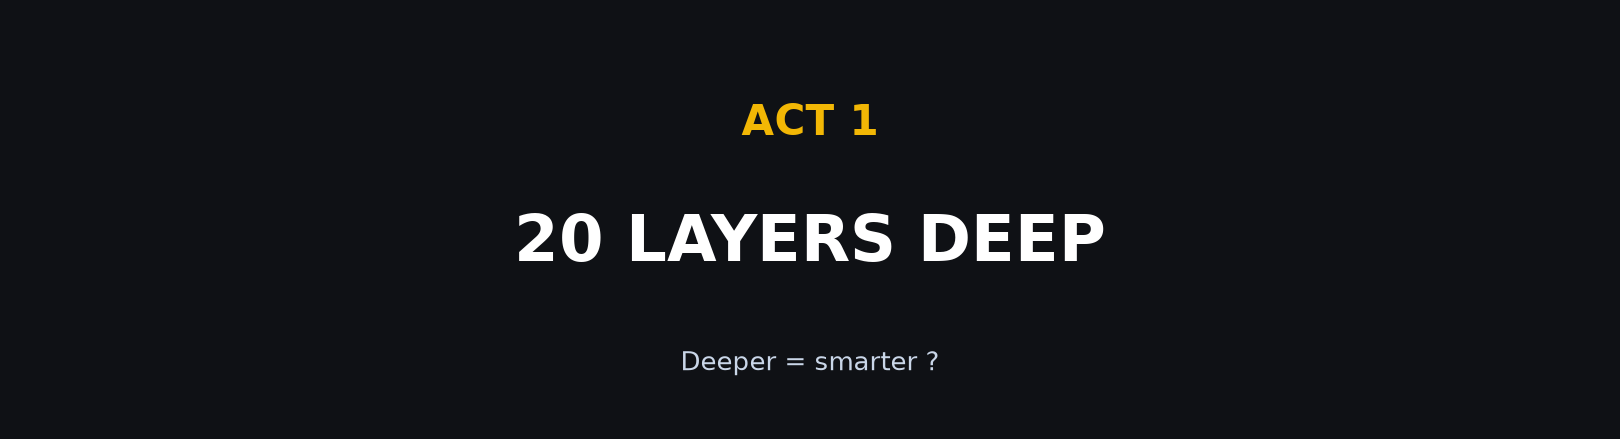

In [11]:
viz.act(1, "20 layers deep",
        "Deeper = smarter ?")

def new_shop_model():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 128), nn.ReLU(),
        nn.Linear(128, 64), nn.ReLU(),
        nn.Linear(64,10),

    )

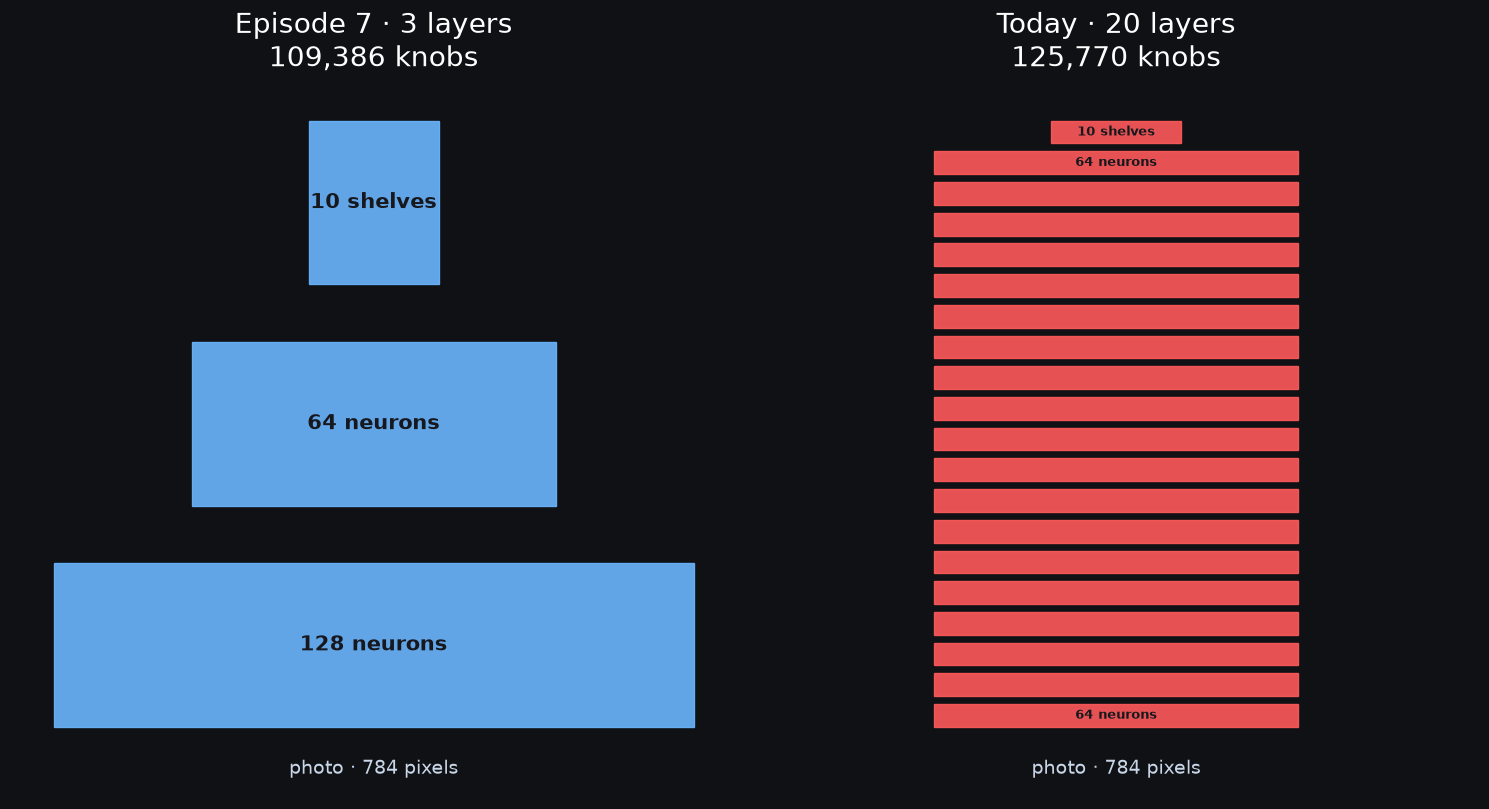

In [12]:
def deep_net(layers = 20, width = 64):
    parts, size = [nn.Flatten()], 784
    for _ in range(layers - 1):                     # 19 hidden layers
        parts += [nn.Linear(size, width), nn.ReLU()]
        size = width
    parts.append(nn.Linear(size, 10))          ## Layer 20 for the 10 shelves
    return nn.Sequential(*parts)

viz.show_depth(new_shop_model(), deep_net())

In [18]:
loss_fn = nn.CrossEntropyLoss()

def study(model, name, epochs = 5, lr = 0.001, sgd = False):
    if sgd:
        optimizer = torch.optim.SGD(model.parameters(), lr = lr)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr = lr)
    loader = DataLoader(TensorDataset(X_train, y_train),
                        batch_size = 64, shuffle = True)
    curve, step, best_acc = [], 0, 0
    for epoch in range(epochs):                         # Training starts from here
        for xb, yb in loader:
            model.train()                              # study mode
            loss = loss_fn(model(xb.to(device)), yb.to(device))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            step += 1
            if step % 10 == 0:
                curve.append(accuracy(model, X_val, y_val))
                viz.race_chart(name, curve, epochs)
                if curve[-1] > best_acc:        # new best
                     best_acc = curve[-1]
                     best = copy.deepcopy(model.state_dict())
    model.load_state_dict(best)                           # best mock test
    return curve
                          

## The race between 3 layers and 20 layers neural network

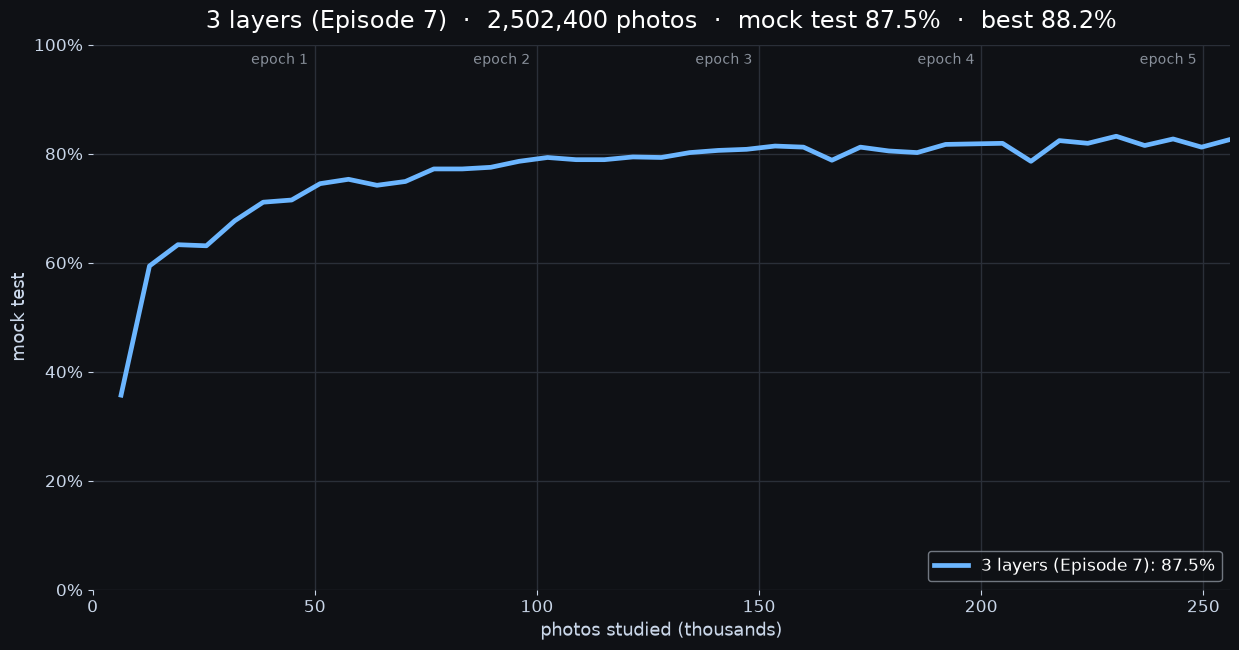

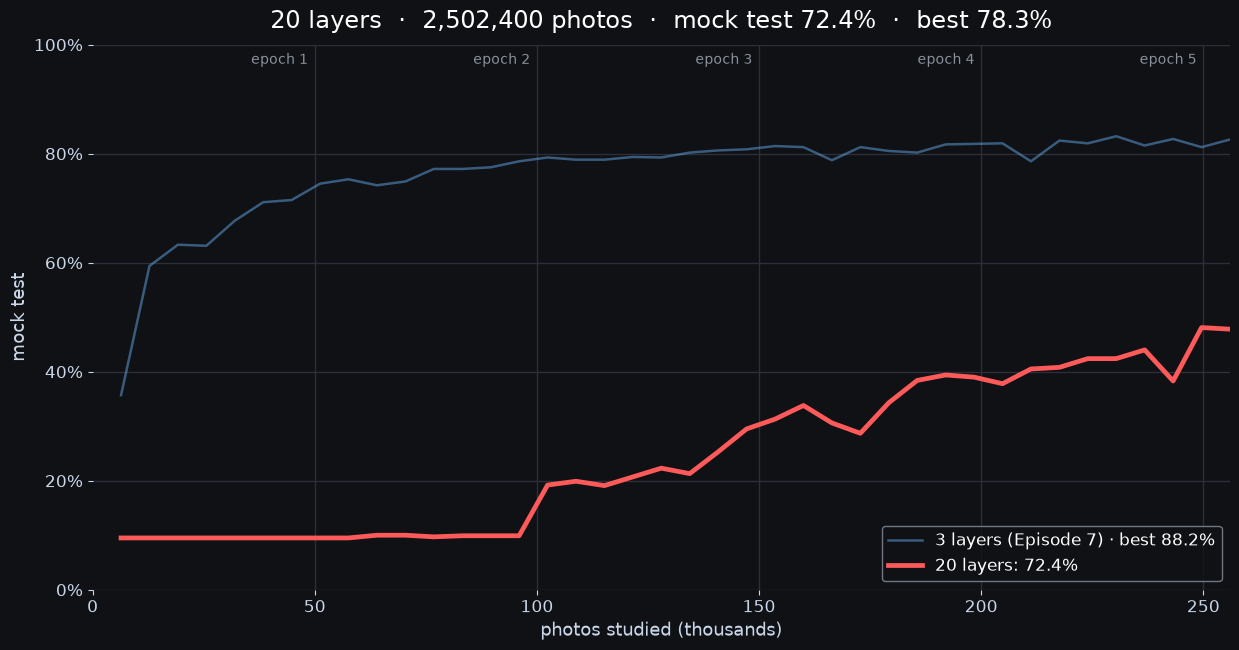

best mock test - 3 layers:  0.882 | 20 layers:  0.783


In [19]:
torch.manual_seed(42)
shallow = new_shop_model().to(device)
shallow_curve = study(shallow, "3 layers (Episode 7)")
torch.manual_seed(42)
deep = deep_net().to(device)
deep_curve = study(deep, "20 layers")
print("best mock test - 3 layers: ", max(shallow_curve),
      "| 20 layers: ", max(deep_curve))

board exam -> 3 layers:  0.872 | 20 layers:  0.772


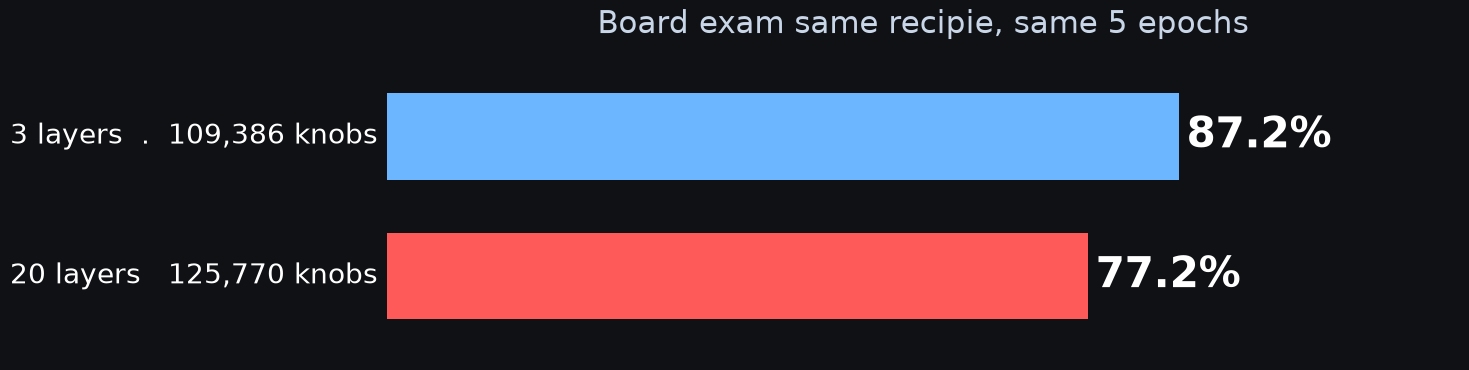

In [20]:
shallow_board = accuracy(shallow, X_test, y_test)
deep_board = accuracy(deep, X_test, y_test)
print("board exam -> 3 layers: ", shallow_board, "| 20 layers: ", deep_board)
viz.reveal_board([("3 layers  .  109,386 knobs", shallow_board, viz.SKY),
                  ("20 layers   125,770 knobs", deep_board, viz.HOT)],
                  "Board exam same recipie, same 5 epochs")

## Neurons sleeping ?

Never fire:  424 of 1216


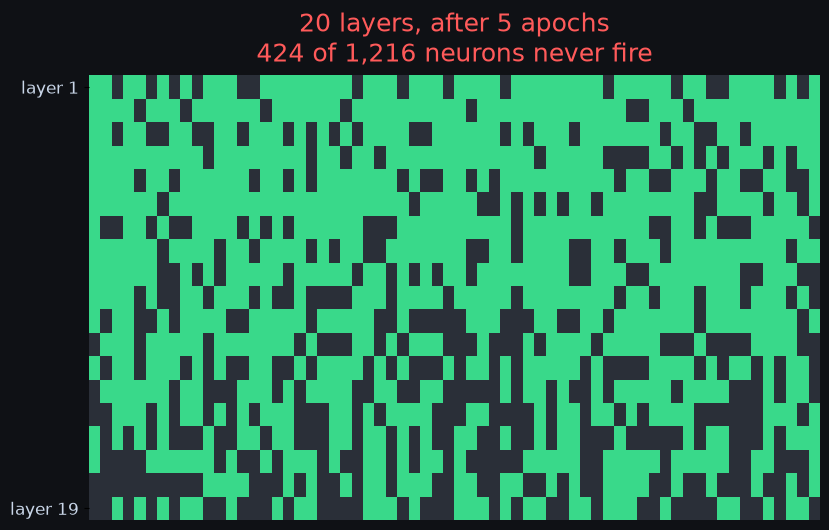

In [21]:
def alive(model, X):
    rows, h = [], X.to(device)
    model.eval()
    with torch.no_grad():
        for layer in model:
            h = layer(h)
            if isinstance(layer, nn.ReLU):
                rows.append((h > 0).any(dim  = 0).cpu())
    return torch.stack(rows)

deep_alive = alive(deep, X_val)
print("Never fire: ",  int((~deep_alive).sum()), "of", deep_alive.numel())
viz.show_brain(deep_alive, "20 layers, after 5 apochs")

## X-Ray of the model 

layer 1:  1.4874343423620928e-10    |  layer 20:  0.0002864889975171536


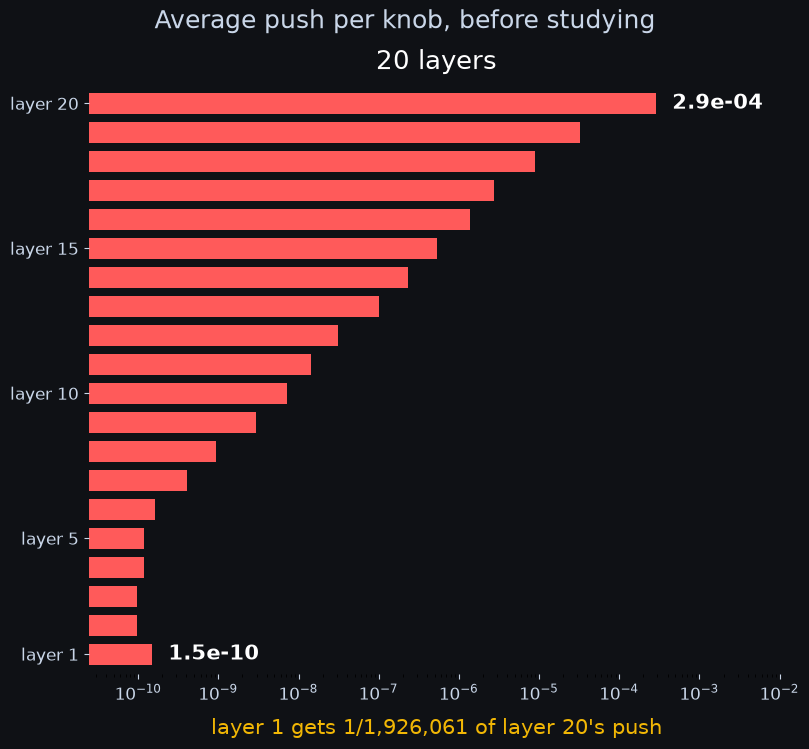

In [22]:
def xray(model):
    model.train()
    xb, yb = X_val[:1000].to(device), y_val[:1000].to(device)
    model.zero_grad()
    loss_fn(model(xb), yb).backward()       # one backward(), no step
    return [layer.weight.grad.abs().mean().item()
            for layer in model if isinstance(layer, nn.Linear)]

torch.manual_seed(42)
push = xray(deep_net().to(device))     # the 20 layers, before study
print(f"layer 1:  {push[0]}    |  layer 20:  {push[-1]}")
viz.show_xray(push, "Average push per knob, before studying")

## With SGD

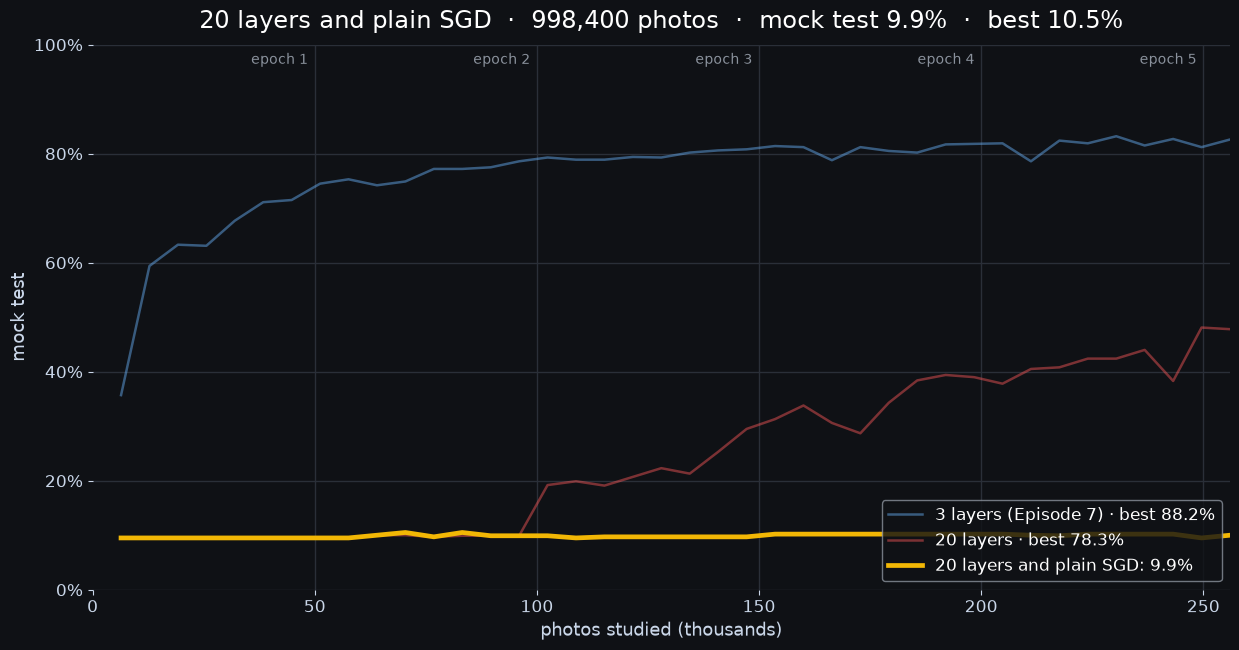

[0, 0, 0, 0, 10000, 0, 0, 0, 0, 0]


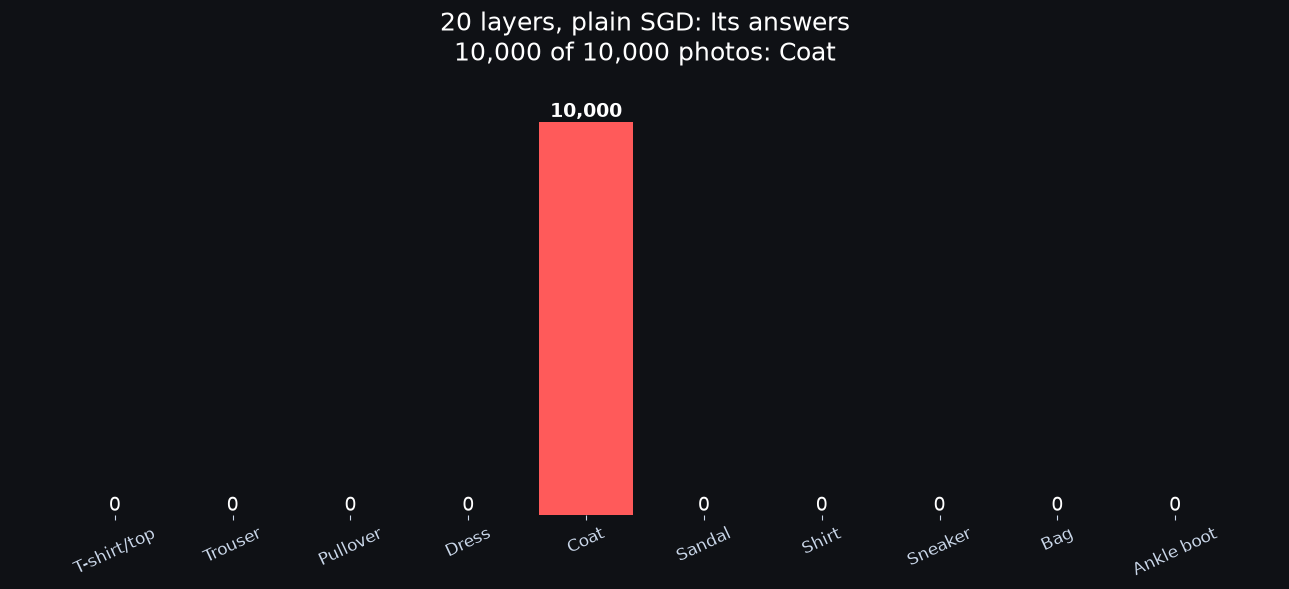

In [23]:
torch.manual_seed(42)
deep_sgd = deep_net().to(device)
sgd_curve = study(deep_sgd, "20 layers and plain SGD", epochs = 2,
                  lr = 0.1, sgd = True)
sgd_counts = torch.bincount(picks(deep_sgd, X_val), minlength = 10)
print(sgd_counts.tolist())
viz.show_picks(sgd_counts, classes, "20 layers, plain SGD: Its answers")

## One line, one layer

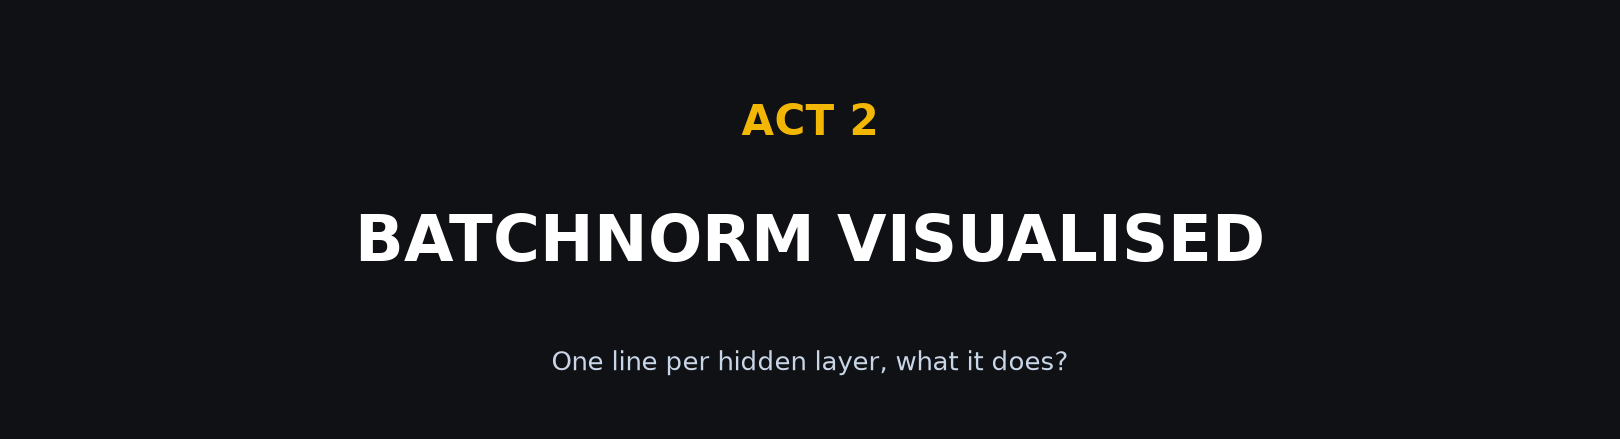

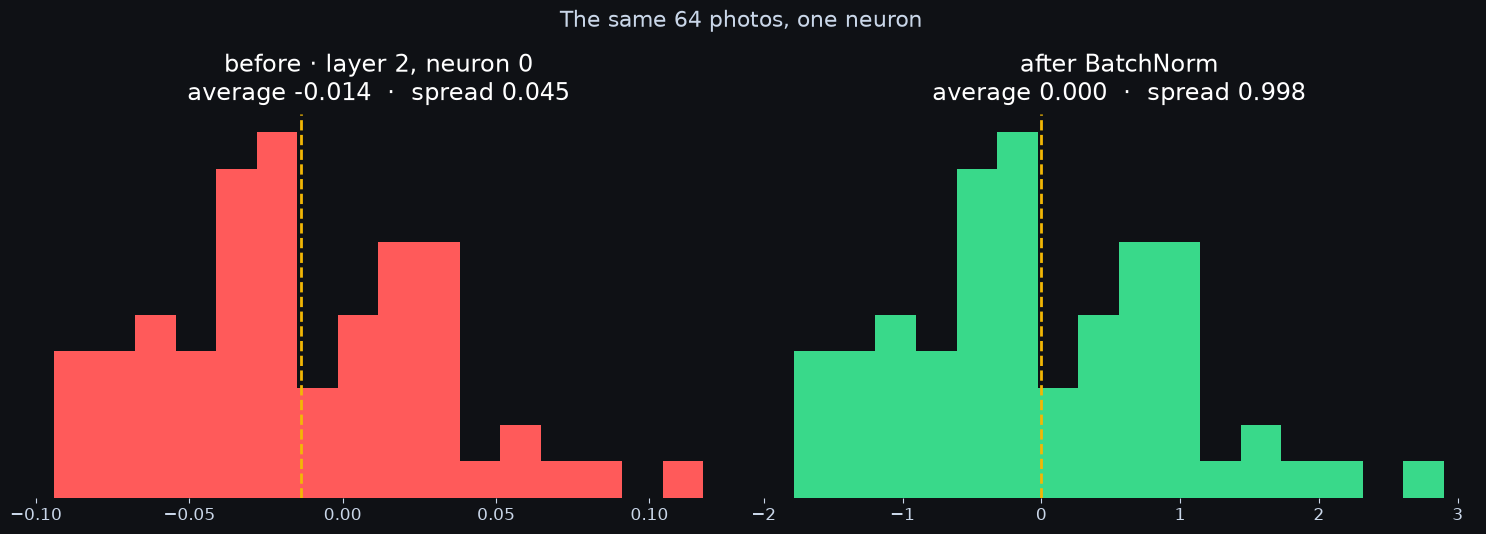

In [24]:
viz.act(2, "BatchNorm visualised",
        "One line per hidden layer, what it does?")
torch.manual_seed(42)
fresh = deep_net().to(device)
with torch.no_grad():
    h = fresh[:4](X_val[:64].to(device))
norm = nn.BatchNorm1d(64).to(device)
after = norm(h).detach()                   # minus average / spread
viz.show_bn(h[:,0], after[:, 0])           # neuron 0

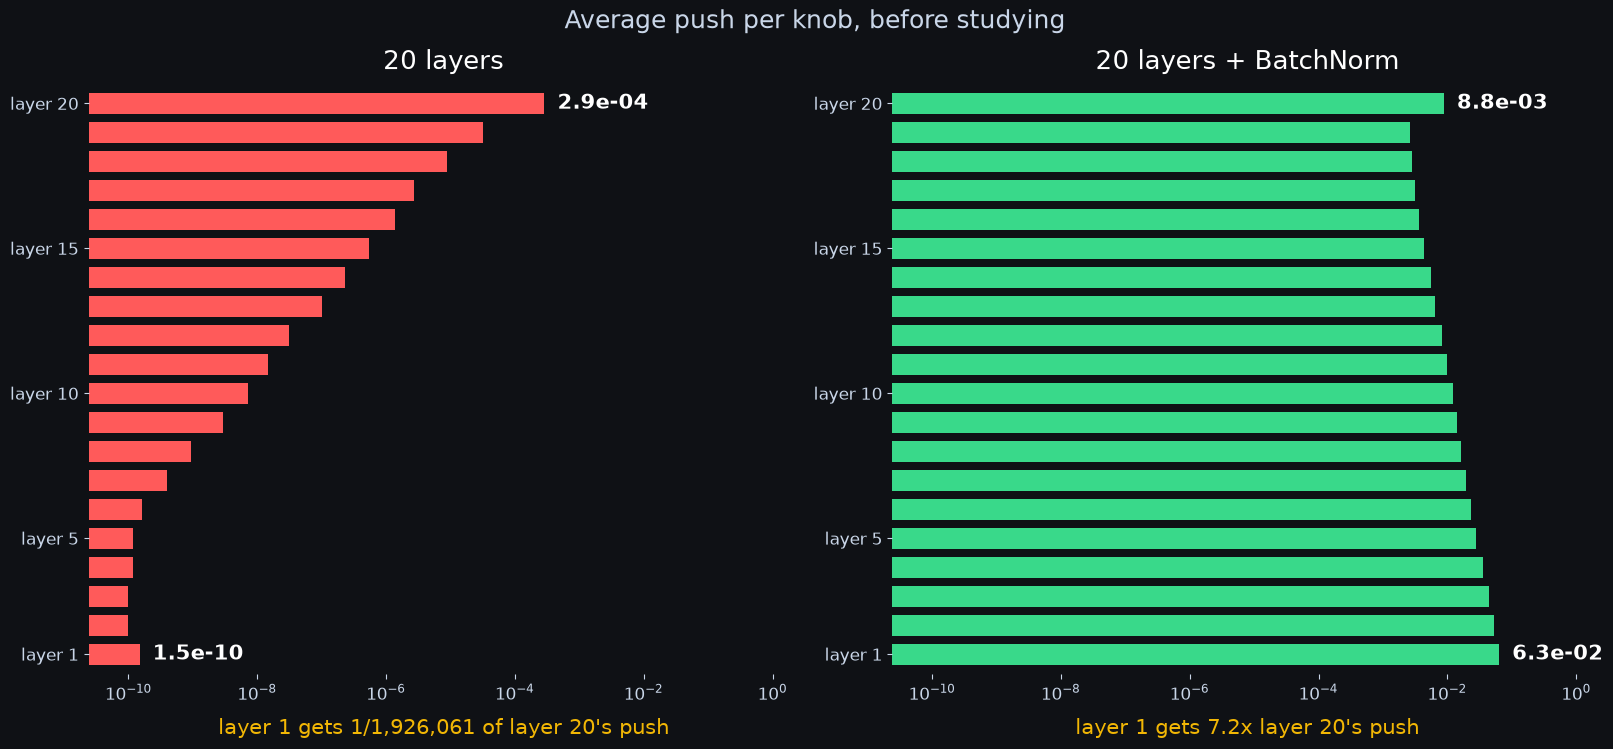

In [26]:
def deep_net(layers = 20, width = 64, bn = False):
    parts, size = [nn.Flatten()], 784
    for _ in range(layers - 1):
        parts.append(nn.Linear(size, width))
        if bn:
            parts.append(nn.BatchNorm1d(width))
        parts.append(nn.ReLU())
        size = width
    parts.append(nn.Linear(size, 10))
    return nn.Sequential(*parts)

torch.manual_seed(42)
push_bn = xray(deep_net(bn = True).to(device))
viz.show_xray(push, "Average push per knob, before studying",
              compare = push_bn)

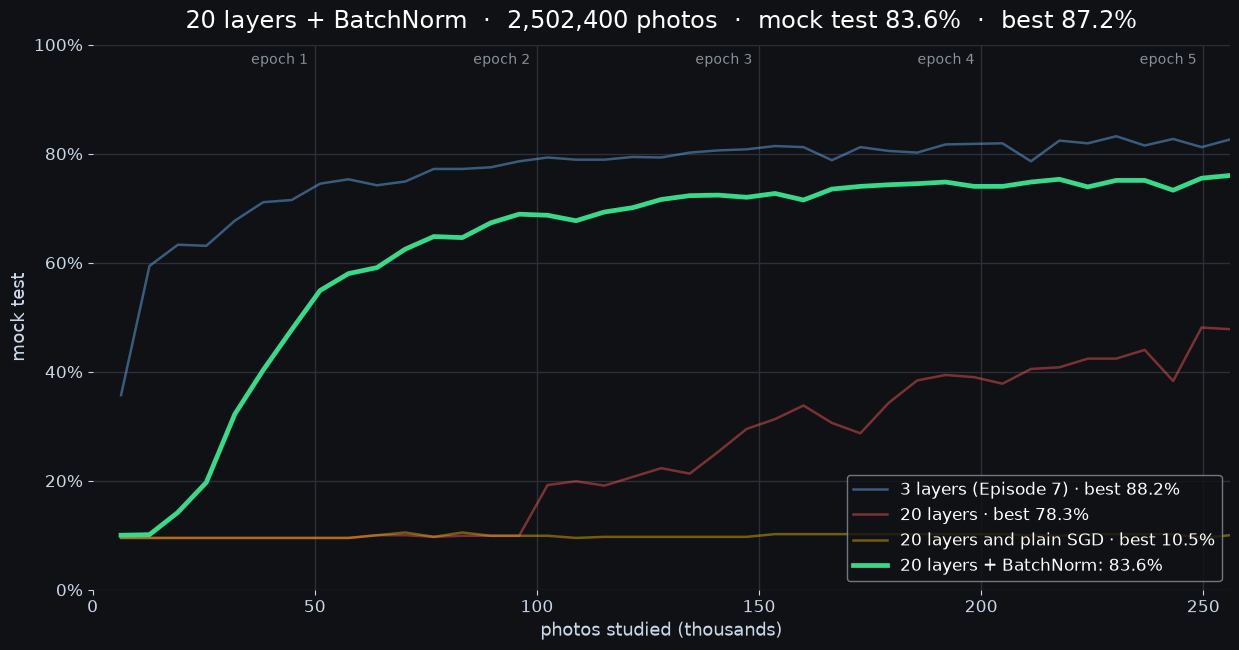

after 6400 photos:  0.095 -> 0.1
Best mock test:  0.783 -> 0.872


In [27]:
torch.manual_seed(42)
deep_bn = deep_net(bn = True).to(device)
bn_curve = study(deep_bn, "20 layers + BatchNorm")
print("after 6400 photos: ", deep_curve[0], "->", bn_curve[0])
print("Best mock test: ", max(deep_curve), "->", max(bn_curve))

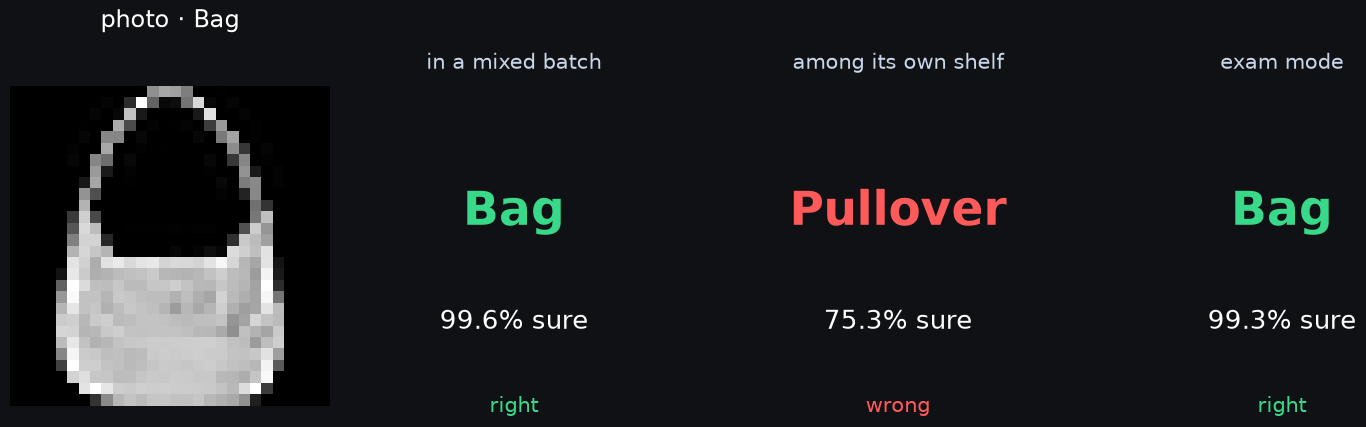

In [28]:
i = 101
photo, shelf = X_val[i: i+1], int(y_val[i])
mixed = torch.cat([photo, X_train[:63]])
own = torch.cat([photo, X_train[y_train == shelf][:63]])
study_copy = copy.deepcopy(deep_bn).train()
with torch.no_grad():
    in_mixed = study_copy(mixed.to(device))[0]
    in_own = study_copy(own.to(device))[0]
    alone = deep_bn.eval()(photo.to(device))[0]
viz.show_company(photo, [("in a mixed batch", in_mixed),
                         ("among its own shelf", in_own),
                         ("exam mode", alone)], classes, shelf)

## Grading in boxes

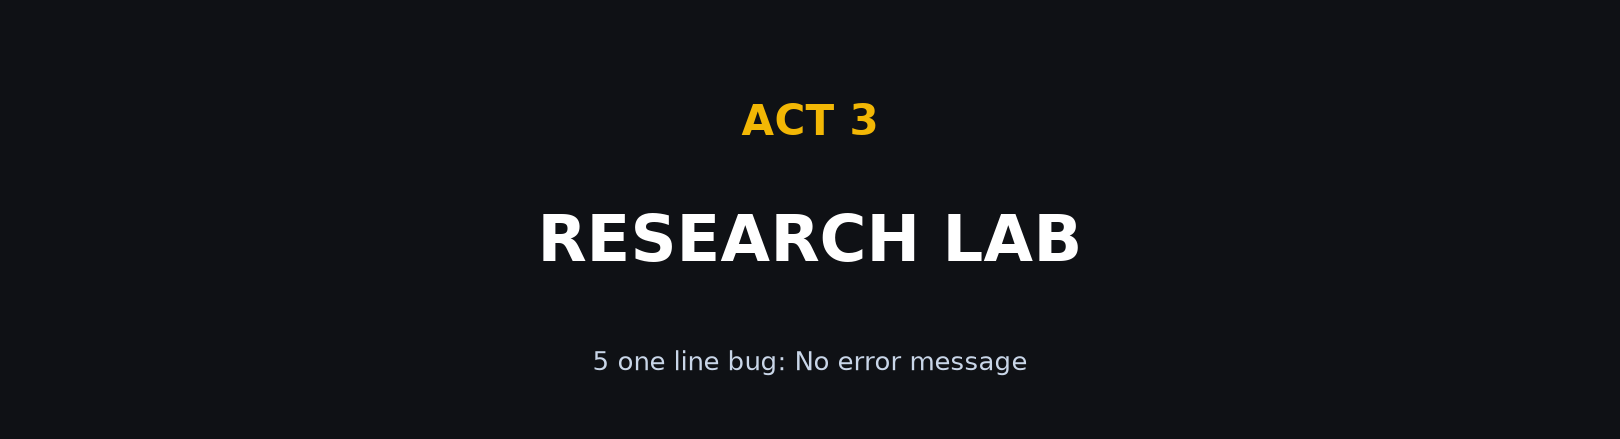

In [29]:
viz.act(3, "research lab", "5 one line bug: No error message")
def box_exam(model):
    order = torch.argsort(y_test, stable = True)
    right = 0
    with torch.no_grad():
        for k in range(0, 10000, 64):
            idx = order[k:k+64]
            guess = model(X_test[idx].to(device)).argmax(dim = 1).cpu()
            right += int((guess == y_test[idx]).sum())
    return right


Exam mode:  8639 of 10000 right
Study mode:  1459 of 10000 right
BOARD EXAM:  0.864 -> after that one test 0.611


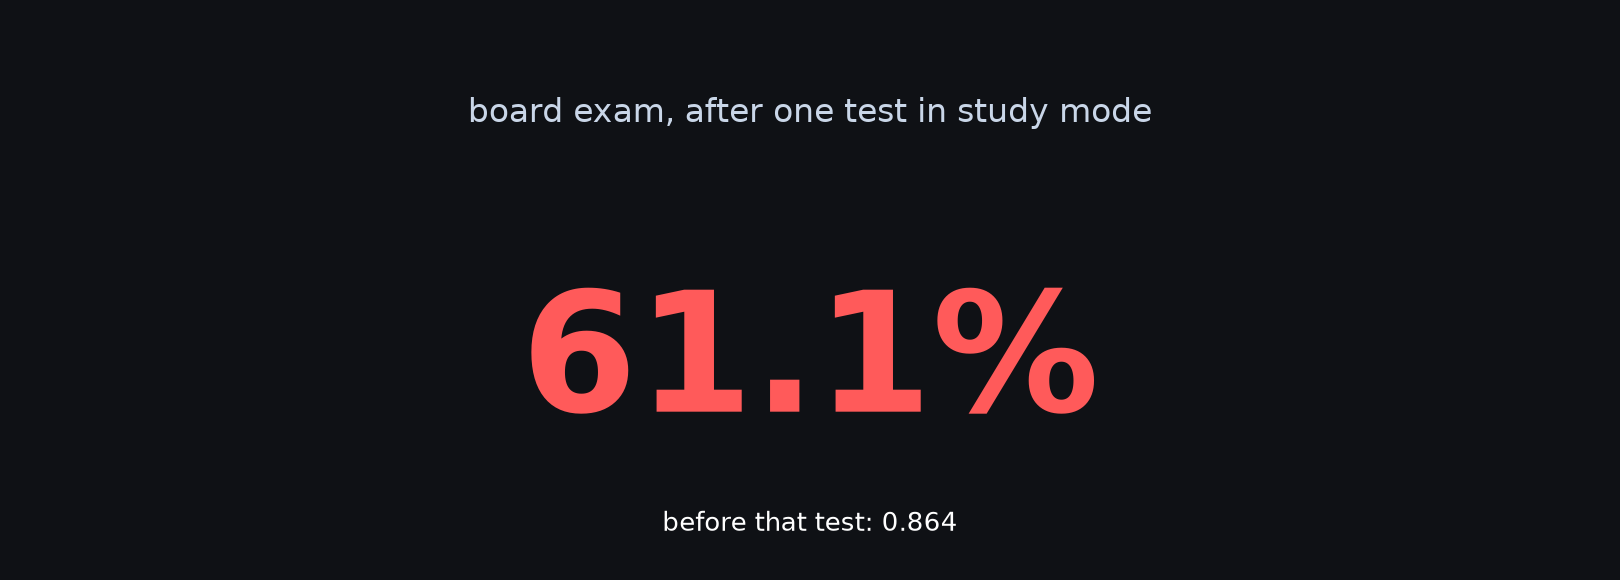

In [30]:
exam = copy.deepcopy(deep_bn)
print("Exam mode: ", box_exam(exam.eval()), "of 10000 right")
exam.train()
print("Study mode: ", box_exam(exam), "of 10000 right")
bn_board = accuracy(deep_bn, X_test, y_test)
after_bug = accuracy(exam, X_test, y_test)
print("BOARD EXAM: ", bn_board, "-> after that one test", after_bug)
viz.reveal("board exam, after one test in study mode", after_bug,
           start = bn_board, colour = viz.HOT,
           note = f"before that test: {bn_board}")

In [31]:
bn_board

0.864

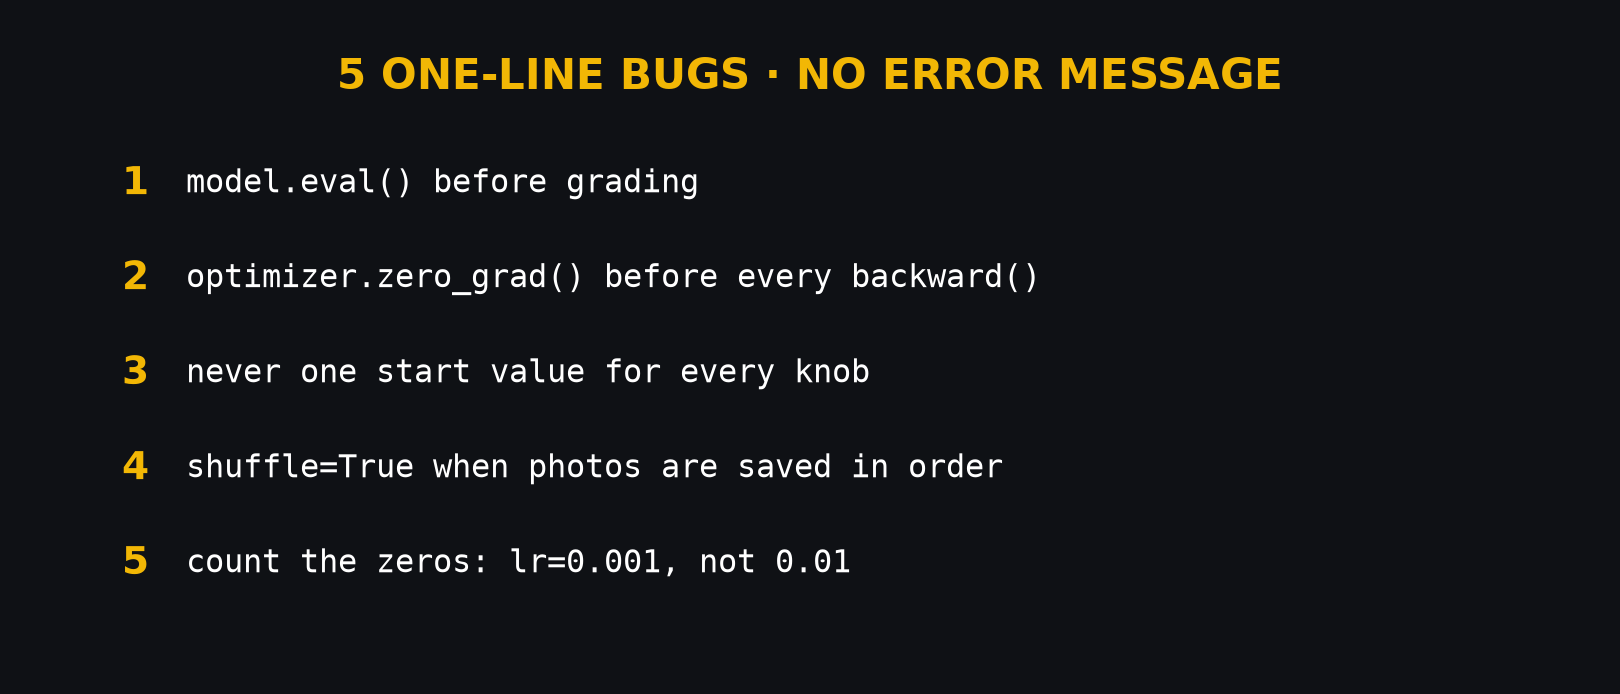

In [32]:
viz.checklist(["model.eval() before grading",
"optimizer.zero_grad() before every backward()",
"never one start value for every knob",
"shuffle=True when photos are saved in order",
"count the zeros: lr=0.001, not 0.01"])

In [5]:
from torch import nn

model = nn.Linear(10, 5)
for p in model.parameters():
    print(p)

Parameter containing:
tensor([[-0.3053, -0.0325, -0.2117,  0.1172, -0.0956,  0.1972,  0.1287, -0.2311,
         -0.2081,  0.2898],
        [-0.2605,  0.0588,  0.0715, -0.1534,  0.0686,  0.1696, -0.2470, -0.2011,
          0.2164, -0.0647],
        [ 0.2433, -0.1530,  0.0592,  0.0233,  0.0585, -0.0244,  0.2987,  0.0995,
          0.0040,  0.3064],
        [-0.0763,  0.1429, -0.1385, -0.0277,  0.1173,  0.2801, -0.1327,  0.0246,
         -0.2934, -0.2548],
        [-0.1894, -0.0307,  0.1878,  0.3113, -0.1440,  0.0571,  0.2121,  0.0548,
         -0.2867, -0.0188]], requires_grad=True)
Parameter containing:
tensor([-0.0790,  0.0866, -0.2455, -0.0574,  0.0188], requires_grad=True)
